# 04 — Baseline KNN (`E0` Standard KNN & `E1` Optimized KNN)

**Modul Inti:** [`src/baseline_knn.py`](../src/baseline_knn.py)  
**Skrip CLI:** [`src/04_baseline_knn.py`](../src/04_baseline_knn.py)  
**Laporan:** [`Laporan_Baseline_KNN_DIFW_KNN.md`](../Laporan_Baseline_KNN_DIFW_KNN.md)

Notebook ini membangun dan menguji jalur **Baseline KNN** pada representasi *StandardScaler + One-Hot Encoding* dengan jarak Euclidean:
1. **Unit Test Ekuivalensi:** Membuktikan fungsi cepat berbasis `NearestNeighbors` identik hingga $< 10^{-9}$ dengan `KNeighborsClassifier`.
2. **Stratified 5-Fold CV Tuning:** Mengevaluasi $k \in \{3, 5, 7, 11, 15, 21, 31, 51, 71, 101\}$ dan `weights` $\in \{\text{'uniform'}, \text{'distance'}\}$ pada `Training / Development Data` (`36.168` baris) bebas *data leakage*.
3. **Evaluasi Hold-out Test (`9.043` baris):** Membandingkan **`E0 (Standard KNN: k=5, uniform)`** dan **`E1 (Optimized KNN)`** lengkap dengan **95% Bootstrap CI** (`n_boot=1000`), Kurva ROC, Kurva Precision–Recall, dan Confusion Matrix.

## 1. Muat Data Split & *Unit Test* Ekuivalensi `NearestNeighbors` vs `KNeighborsClassifier`

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve, roc_curve
from IPython.display import display

plt.rcParams.update({
    'figure.dpi': 120, 'axes.edgecolor': '#CCCCCC', 'axes.grid': True,
    'grid.alpha': 0.3, 'grid.linestyle': '--', 'axes.titleweight': 'bold',
})

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.preprocessing import BaselineEuclideanPreprocessor
from src.baseline_knn import (
    METRIC_KEYS, evaluate_holdout_model,
    run_stratified_cv_grid, verify_knn_probability_equivalence
)

processed_dir = PROJECT_ROOT / 'data' / 'processed'
train_df = pd.read_csv(processed_dir / 'train_split.csv')
test_df = pd.read_csv(processed_dir / 'test_split.csv')
folds_df = pd.read_csv(processed_dir / 'train_cv_folds.csv')

X_train_df = train_df.drop(columns=['y'])
y_train = train_df['y'].to_numpy(dtype=np.int64)
X_test_df = test_df.drop(columns=['y'])
y_test = test_df['y'].to_numpy(dtype=np.int64)
fold_ids = folds_df['fold_id'].to_numpy(dtype=np.int64)

val0 = fold_ids == 0
prep0 = BaselineEuclideanPreprocessor()
X_tr0 = prep0.fit_transform(X_train_df.loc[~val0].reset_index(drop=True))
X_va0 = prep0.transform(X_train_df.loc[val0].reset_index(drop=True))
eq_df = verify_knn_probability_equivalence(X_tr0, y_train[~val0], X_va0)
print(f'Train shape={X_train_df.shape}, Test shape={X_test_df.shape}')
display(eq_df)

Train shape=(36168, 15), Test shape=(9043, 15)


,k,weights,max_prob_abs_diff_k,max_dist_trunc_diff,n_boundary_tie_rows_maxk,status
0,5,uniform,0.000000e+00,0.0,2,PASS
1,5,distance,2.220446e-16,0.0,2,PASS
2,21,uniform,0.000000e+00,0.0,0,PASS
3,21,distance,3.330669e-16,0.0,0,PASS


## 2. Stratified 5-Fold Cross-Validation Hyperparameter Tuning

Best CV F1/MCC : k=3, weights='uniform' -> F1=0.3131, MCC=0.2746, PR-AUC=0.2474
Best CV PR-AUC : k=51, weights='distance' -> PR-AUC=0.3912, ROC-AUC=0.7605, F1=0.2247


,weights,k,accuracy_mean,precision_yes_mean,recall_yes_mean,f1_yes_mean,pr_auc_mean,roc_auc_mean,mcc_mean,g_mean_mean
0,distance,3,0.8753,0.4394,0.2401,0.3104,0.2709,0.6679,0.2622,0.4796
1,distance,5,0.8838,0.5078,0.2113,0.2982,0.3105,0.6925,0.2750,0.4531
2,distance,7,0.8878,0.5563,0.1997,0.2938,0.3315,0.7092,0.2862,0.4419
3,distance,11,0.8897,0.5944,0.1799,0.2760,0.3562,0.7271,0.2845,0.4202
4,distance,15,0.8902,0.6121,0.1676,0.2631,0.3683,0.7349,0.2802,0.4061
5,distance,21,0.8916,0.6453,0.1636,0.2609,0.3787,0.7433,0.2873,0.4019
6,distance,31,0.8919,0.6670,0.1517,0.2471,0.3874,0.7519,0.2829,0.3875
7,distance,51,0.8913,0.6788,0.1347,0.2247,0.3912,0.7605,0.2694,0.3654
8,distance,71,0.8908,0.6864,0.1229,0.2084,0.3893,0.7642,0.2590,0.3490
9,distance,101,0.8906,0.7004,0.1130,0.1945,0.3889,0.7663,0.2517,0.3349


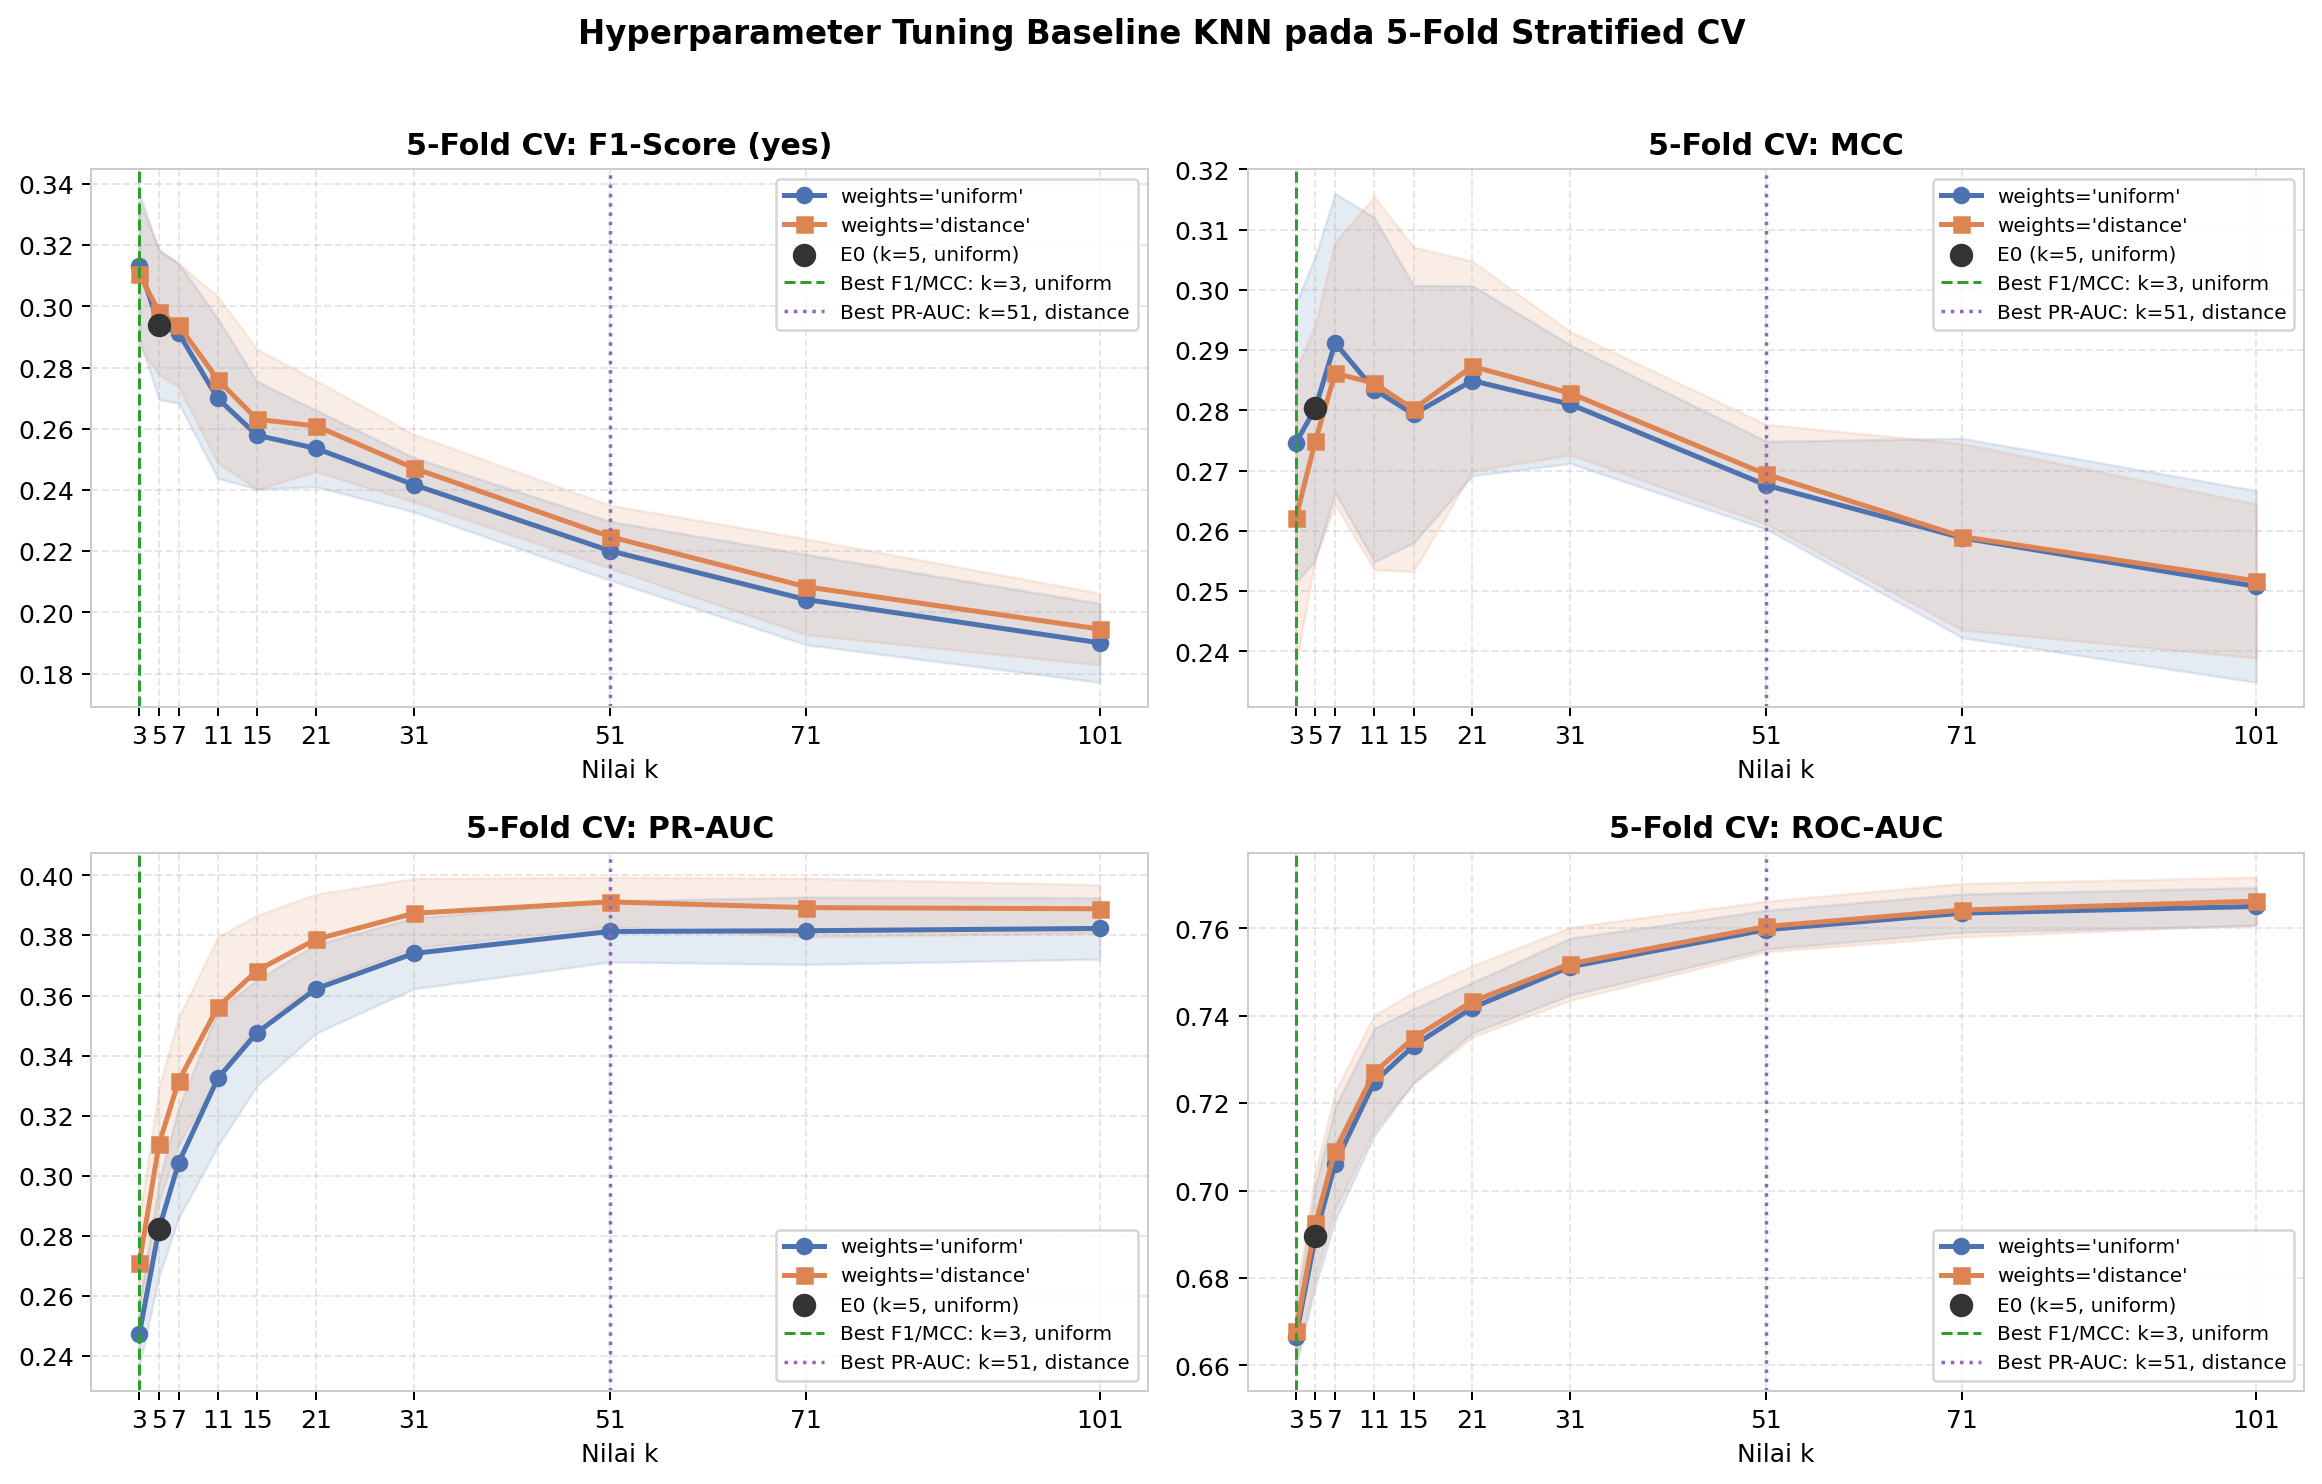

In [2]:
K_GRID = [3, 5, 7, 11, 15, 21, 31, 51, 71, 101]
WEIGHTS_GRID = ['uniform', 'distance']

per_fold_df, cv_summary = run_stratified_cv_grid(
    X_train_df=X_train_df, y_train=y_train, fold_ids=fold_ids,
    k_grid=K_GRID, weights_grid=WEIGHTS_GRID
)

best_f1_row = cv_summary.sort_values(['f1_yes_mean', 'mcc_mean', 'pr_auc_mean'], ascending=False).iloc[0]
best_prauc_row = cv_summary.sort_values(['pr_auc_mean', 'roc_auc_mean', 'f1_yes_mean'], ascending=False).iloc[0]

print(f"Best CV F1/MCC : k={int(best_f1_row['k'])}, weights='{best_f1_row['weights']}' -> F1={best_f1_row['f1_yes_mean']:.4f}, MCC={best_f1_row['mcc_mean']:.4f}, PR-AUC={best_f1_row['pr_auc_mean']:.4f}")
print(f"Best CV PR-AUC : k={int(best_prauc_row['k'])}, weights='{best_prauc_row['weights']}' -> PR-AUC={best_prauc_row['pr_auc_mean']:.4f}, ROC-AUC={best_prauc_row['roc_auc_mean']:.4f}, F1={best_prauc_row['f1_yes_mean']:.4f}")

disp_cols = ['weights', 'k', 'accuracy_mean', 'precision_yes_mean', 'recall_yes_mean', 'f1_yes_mean', 'pr_auc_mean', 'roc_auc_mean', 'mcc_mean', 'g_mean_mean']
display(cv_summary[disp_cols].round(4))

fig, axes = plt.subplots(2, 2, figsize=(13, 8.4))
panels = [('f1_yes', '5-Fold CV: F1-Score (yes)'), ('mcc', '5-Fold CV: MCC'), ('pr_auc', '5-Fold CV: PR-AUC'), ('roc_auc', '5-Fold CV: ROC-AUC')]
colors = {'uniform': '#4C72B0', 'distance': '#DD8452'}
markers = {'uniform': 'o', 'distance': 's'}
for ax, (metric, title) in zip(axes.flat, panels):
    for w in WEIGHTS_GRID:
        sub = cv_summary[cv_summary['weights'] == w].sort_values('k')
        kv, mv, sv = sub['k'].to_numpy(), sub[f'{metric}_mean'].to_numpy(), sub[f'{metric}_std'].to_numpy()
        ax.plot(kv, mv, marker=markers[w], color=colors[w], linewidth=2, label=f"weights='{w}'")
        ax.fill_between(kv, mv - sv, mv + sv, color=colors[w], alpha=0.14)
    e0_sub = cv_summary[(cv_summary['k'] == 5) & (cv_summary['weights'] == 'uniform')].iloc[0]
    ax.scatter([5], [e0_sub[f'{metric}_mean']], color='#333333', s=70, zorder=5, label='E0 (k=5, uniform)')
    ax.axvline(int(best_f1_row['k']), color='#2CA02C', linestyle='--', linewidth=1.2, label=f"Best F1/MCC: k={int(best_f1_row['k'])}, {best_f1_row['weights']}")
    if int(best_prauc_row['k']) != int(best_f1_row['k']) or best_prauc_row['weights'] != best_f1_row['weights']:
        ax.axvline(int(best_prauc_row['k']), color='#9467BD', linestyle=':', linewidth=1.4, label=f"Best PR-AUC: k={int(best_prauc_row['k'])}, {best_prauc_row['weights']}")
    ax.set_title(title)
    ax.set_xlabel('Nilai k')
    ax.set_xticks(K_GRID)
    ax.legend(fontsize=8)
fig.suptitle('Hyperparameter Tuning Baseline KNN pada 5-Fold Stratified CV', fontsize=13, fontweight='bold')
fig.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 3. Evaluasi Akhir pada Hold-out Test Set (`9.043` Observasi)

In [3]:
models_to_eval = [
    ('E0', 'Standard KNN', 5, 'uniform'),
    ('E1', 'Optimized KNN', int(best_f1_row['k']), str(best_f1_row['weights'])),
]
if int(best_prauc_row['k']) != int(best_f1_row['k']) or str(best_prauc_row['weights']) != str(best_f1_row['weights']):
    models_to_eval.append(('E1-PR', 'Optimized KNN (Best CV PR-AUC)', int(best_prauc_row['k']), str(best_prauc_row['weights'])))

holdout_results, probs_map = [], {}
for mid, mname, kv, wv in models_to_eval:
    res, yp = evaluate_holdout_model(
        X_train_df=X_train_df, y_train=y_train, X_test_df=X_test_df, y_test=y_test,
        k=kv, weights=wv, model_id=mid, model_name=mname, n_boot=1000, random_state=42
    )
    holdout_results.append(res)
    probs_map[mid] = yp

holdout_df = pd.DataFrame(holdout_results)
show_cols = ['model_id', 'model_name', 'k', 'weights', 'accuracy', 'precision_yes', 'recall_yes', 'f1_yes', 'pr_auc', 'roc_auc', 'mcc', 'g_mean', 'fit_sec', 'predict_sec']
display(holdout_df[show_cols].round(4))
display(holdout_df[['model_id', 'model_name', 'tn', 'fp', 'fn', 'tp']])

,model_id,model_name,k,weights,accuracy,precision_yes,recall_yes,f1_yes,pr_auc,roc_auc,mcc,g_mean,fit_sec,predict_sec
0,E0,Standard KNN,5,uniform,0.8884,0.5650,0.2013,0.2969,0.2921,0.7014,0.2907,0.4441,0.3185,0.6876
1,E1,Optimized KNN,3,uniform,0.8816,0.4876,0.2420,0.3234,0.2619,0.6779,0.2863,0.4835,0.3615,0.7670
2,E1-PR,Optimized KNN (Best CV PR-AUC),51,distance,0.8924,0.7094,0.1361,0.2284,0.4042,0.7656,0.2793,0.3676,0.2880,0.8019


,model_id,model_name,tn,fp,fn,tp
0,E0,Standard KNN,7821,164,845,213
1,E1,Optimized KNN,7716,269,802,256
2,E1-PR,Optimized KNN (Best CV PR-AUC),7926,59,914,144


## 4. Kurva ROC, Precision–Recall, Perbandingan Metrik (95% CI), dan Confusion Matrix

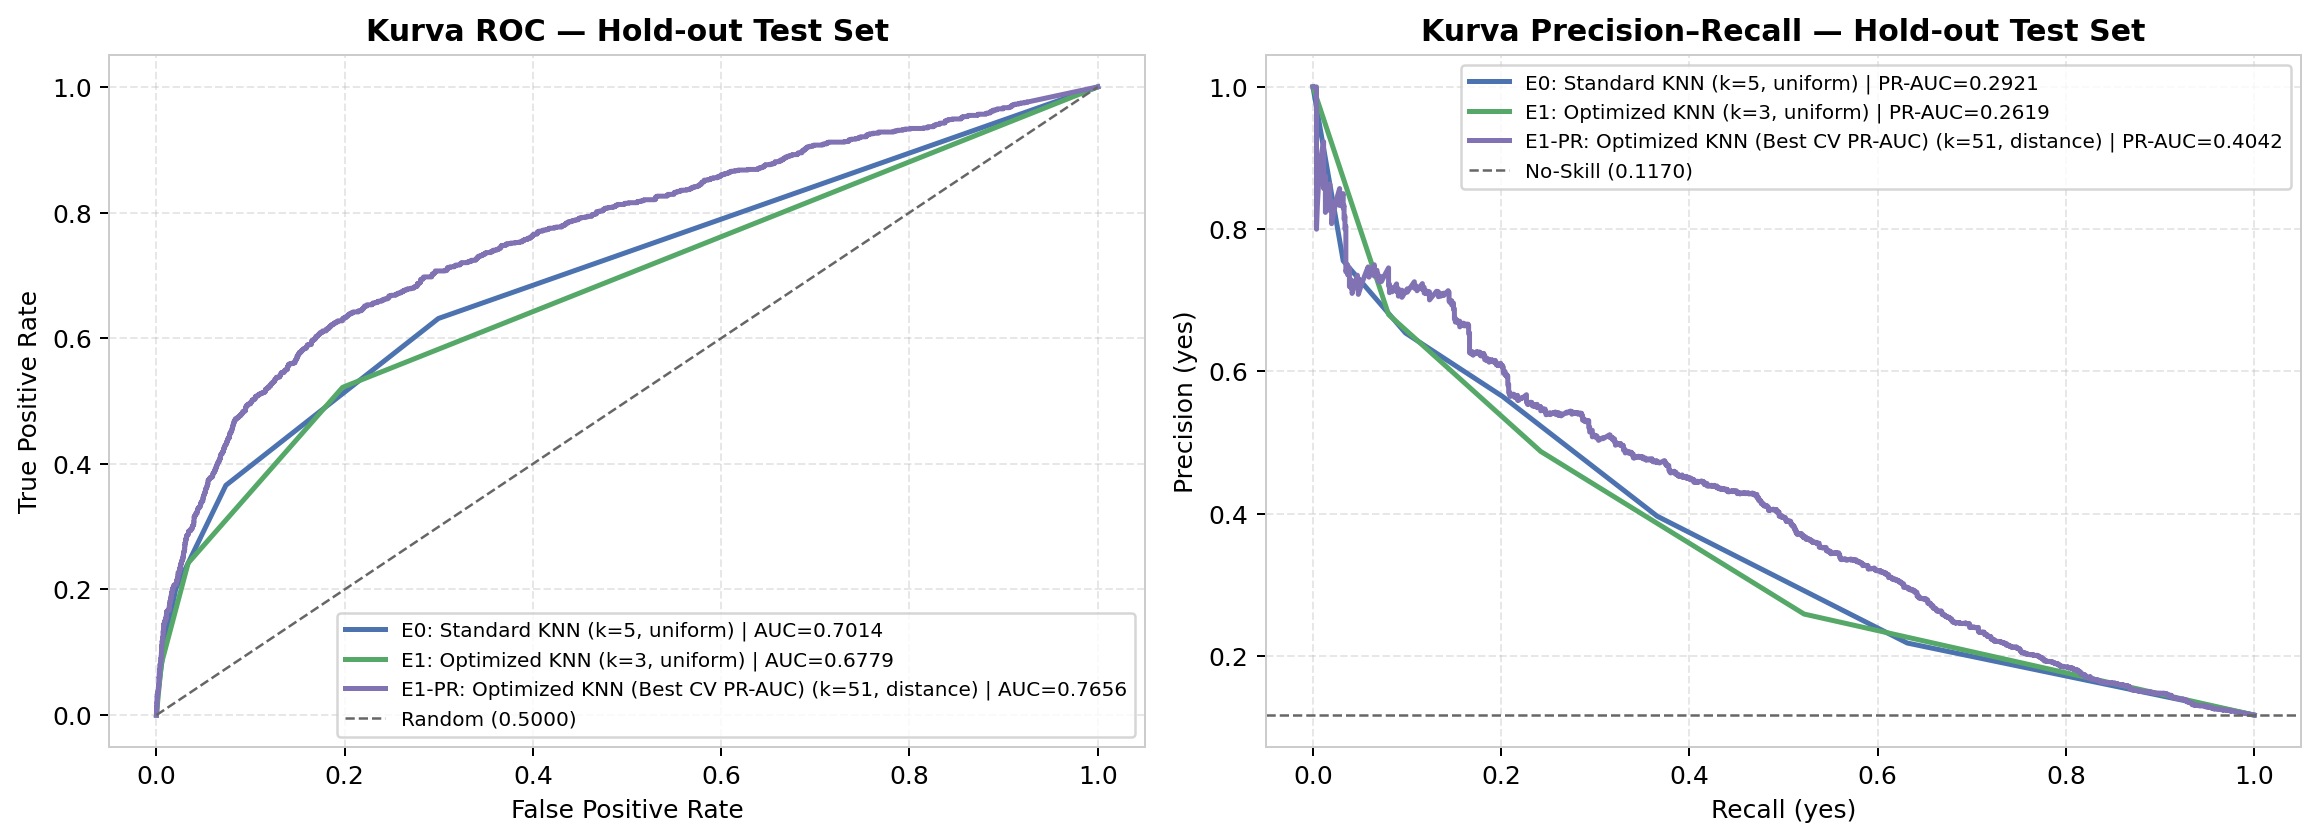

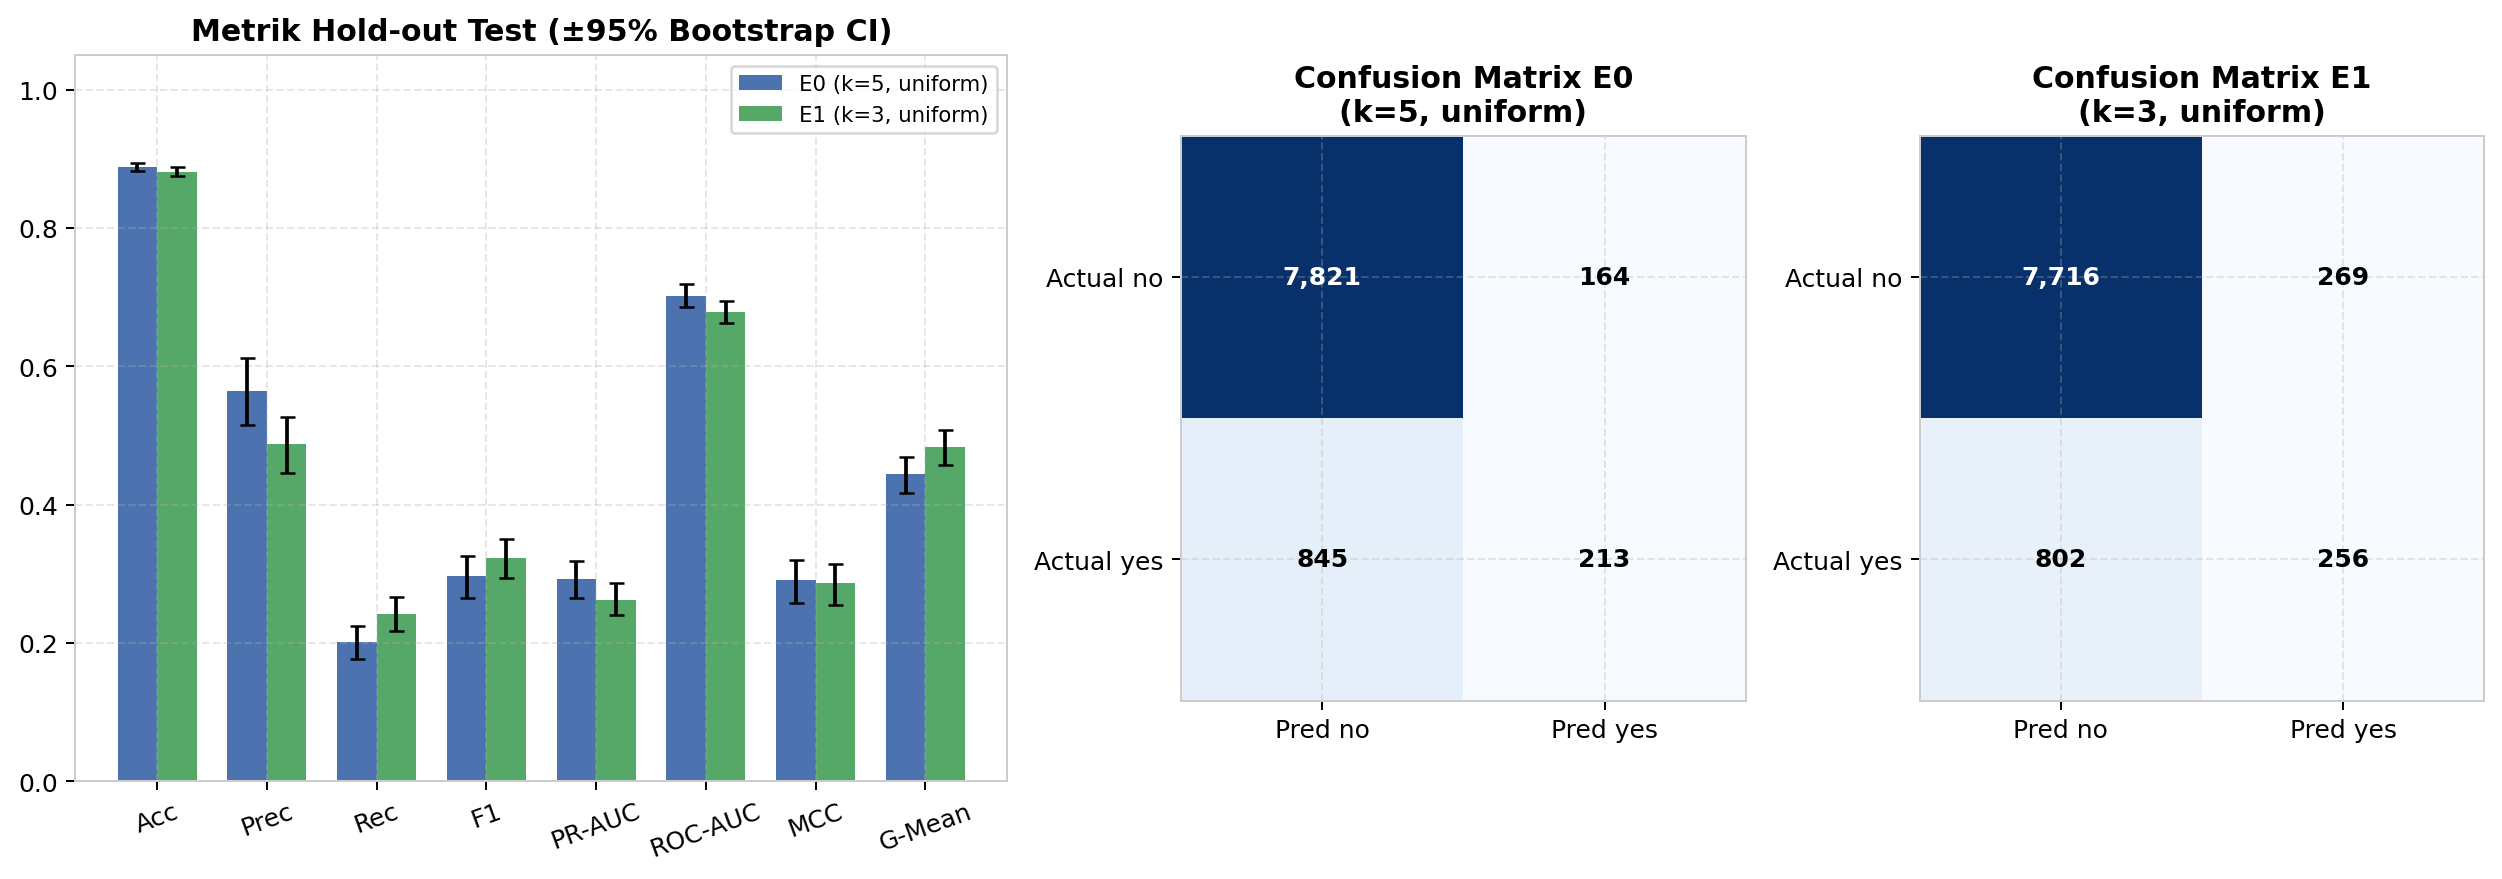

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
palette = ['#4C72B0', '#55A868', '#8172B3']
for idx, res in enumerate(holdout_results):
    mid = res['model_id']
    lbl = f"{mid}: {res['model_name']} (k={res['k']}, {res['weights']})"
    yp = probs_map[mid]
    fpr, tpr, _ = roc_curve(y_test, yp)
    prec, rec, _ = precision_recall_curve(y_test, yp)
    axes[0].plot(fpr, tpr, color=palette[idx % len(palette)], linewidth=2, label=f"{lbl} | AUC={res['roc_auc']:.4f}")
    axes[1].plot(rec, prec, color=palette[idx % len(palette)], linewidth=2, label=f"{lbl} | PR-AUC={res['pr_auc']:.4f}")
axes[0].plot([0, 1], [0, 1], color='#666666', linestyle='--', linewidth=1, label='Random (0.5000)')
axes[0].set_title('Kurva ROC — Hold-out Test Set')
axes[0].set_xlabel('False Positive Rate')
axes[0].set_ylabel('True Positive Rate')
axes[0].legend(fontsize=8, loc='lower right')
axes[1].axhline(float(y_test.mean()), color='#666666', linestyle='--', linewidth=1, label=f'No-Skill ({y_test.mean():.4f})')
axes[1].set_title('Kurva Precision–Recall — Hold-out Test Set')
axes[1].set_xlabel('Recall (yes)')
axes[1].set_ylabel('Precision (yes)')
axes[1].legend(fontsize=8, loc='upper right')
fig.tight_layout()
plt.show()

e0_r, e1_r = holdout_results[0], holdout_results[1]
fig = plt.figure(figsize=(14, 5.0))
gs = fig.add_gridspec(1, 3, width_ratios=[1.65, 1.0, 1.0])
ax_b = fig.add_subplot(gs[0, 0])
xm = np.arange(len(METRIC_KEYS))
e0_err = np.array([[e0_r[m] - e0_r[f'{m}_ci95_low'], e0_r[f'{m}_ci95_high'] - e0_r[m]] for m in METRIC_KEYS]).T
e1_err = np.array([[e1_r[m] - e1_r[f'{m}_ci95_low'], e1_r[f'{m}_ci95_high'] - e1_r[m]] for m in METRIC_KEYS]).T
ax_b.bar(xm - 0.18, [e0_r[m] for m in METRIC_KEYS], width=0.36, yerr=e0_err, capsize=3, color='#4C72B0', label=f"E0 (k={e0_r['k']}, {e0_r['weights']})")
ax_b.bar(xm + 0.18, [e1_r[m] for m in METRIC_KEYS], width=0.36, yerr=e1_err, capsize=3, color='#55A868', label=f"E1 (k={e1_r['k']}, {e1_r['weights']})")
ax_b.set_xticks(xm)
ax_b.set_xticklabels(['Acc', 'Prec', 'Rec', 'F1', 'PR-AUC', 'ROC-AUC', 'MCC', 'G-Mean'], rotation=20)
ax_b.set_ylim(0, 1.05)
ax_b.set_title('Metrik Hold-out Test (±95% Bootstrap CI)')
ax_b.legend(fontsize=8.5)
for idx_c, r in enumerate([e0_r, e1_r]):
    ax_c = fig.add_subplot(gs[0, 1 + idx_c])
    cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
    ax_c.imshow(cm, cmap='Blues')
    ax_c.set_xticks([0, 1]); ax_c.set_yticks([0, 1])
    ax_c.set_xticklabels(['Pred no', 'Pred yes']); ax_c.set_yticklabels(['Actual no', 'Actual yes'])
    ax_c.set_title(f"Confusion Matrix {r['model_id']}\n(k={r['k']}, {r['weights']})")
    th = cm.max() / 2.0
    for rr in range(2):
        for cc in range(2):
            ax_c.text(cc, rr, f'{cm[rr, cc]:,}', ha='center', va='center', color='white' if cm[rr, cc] > th else 'black', fontweight='bold')
fig.tight_layout()
plt.show()